# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170253          # <-- your full roll number
NAME = "Vineet Tripathi"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170253   Name: Vineet Tripathi   Fingerprint: AFA69544   Tickets: 15

Ticket_ID                                                                      Ticket_Text
      T01                             The server is showing an error. It worked yesterday.
      T02     WiFi stopped responding while uploading the file. Is there another solution?
      T03                        The Matlab stopped responding. Is there another solution?
      T04 I reinstalled the password when I use mobile hotspot. Is there another solution?
      T05      I tried restarting the password during the lab. I have tried several times!
      T06                                  The projector has stopped syncing. Please help.
      T07                      The printer has stopped syncing. I don't know what changed.
      T08                                            The Wi-Fi works, but the VPN doesn't.
      T09                                                    Version 2.0.1 crashes at 99%.
   

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
from collections import Counter
import pandas as pd

results = {}
rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    results[tid] = r
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punct": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })

q1 = pd.DataFrame(rows)
total_row = {"Ticket_ID": "TOTAL"}
total_row.update(q1.drop(columns="Ticket_ID").sum().to_dict())
q1_table = pd.concat([q1, pd.DataFrame([total_row])], ignore_index=True)
print(q1_table.to_string(index=False))

corpus_unique = len(set(t for r in results.values() for t in r["tokens"]))
print(f"\nNote: the TOTAL of Unique_Tokens is the sum of per-ticket counts; "
      f"unique tokens across the whole corpus = {corpus_unique}")

# Actual tokens for the two focus tickets
for tid in FOCUS:
    r = results[tid]
    text = df.loc[df["Ticket_ID"] == tid, "Ticket_Text"].iloc[0]
    print(f"\n=== {tid}: {text}")
    print(f"  sentences : {r['sentences']}")
    print(f"  tokens    : {r['tokens']}")
    print(f"  punct     : {r['punct']}")
    print(f"  stopwords : {r['stops']}")
    print(f"  final     : {r['final']}")

Ticket_ID  Sentences  Tokens  Punct  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      11      2          4             10             5
      T02          2      13      2          4             13             7
      T03          2      10      2          3             10             5
      T04          2      15      2          6             14             7
      T05          2      15      2          6             12             7
      T06          2       9      2          2              8             5
      T07          2      13      2          5             12             6
      T08          1      10      2          4              9             4
      T09          1       7      2          1              7             4
      T10          2      14      2          6             13             6
      T11          2      16      2          6             15             8
      T12          2       7      2          3              6             2
      T13   

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

**Observe — answer:** The non-words come from `word_tokenize` (Penn Treebank rules), which splits contractions into a stem plus a clitic: `don't` → `do` + `n't`, `can't` → `ca` + `n't`, `doesn't` → `does` + `n't`. The first half (`do`, `does`) is a stopword and gets removed, but `n't` and the broken stem `ca` are not in NLTK's stopword list, so they survive into the final tokens. Other final tokens that are not ordinary words (e.g. `2.0.1`, `99`, `1023-03-021`, `wi-fi`) are identifiers/numbers kept whole by the tokenizer. The cell below lists the exact tokens in *your* data.

In [6]:
CLITICS = {"n't", "'s", "'re", "'ve", "'ll", "'m", "'d"}
print("Contraction fragments produced by word_tokenize (stem + clitic) and whether they survive into 'final':")
for tid, r in results.items():
    toks = r["tokens"]
    for i, t in enumerate(toks):
        if t in CLITICS and i > 0:
            prev = toks[i - 1]
            print(f"  {tid}: {prev!r} + {t!r}   -> {prev!r} in final: {prev in r['final']}, {t!r} in final: {t in r['final']}")

all_final = [t for r in results.values() for t in r["final"]]
non_alpha = Counter(t for t in all_final if not t.replace("-", "").isalpha())
print("\nOther non-alphabetic final tokens (numbers / identifiers / hyphenated):", dict(non_alpha))

Contraction fragments produced by word_tokenize (stem + clitic) and whether they survive into 'final':
  T07: 'do' + "n't"   -> 'do' in final: False, "n't" in final: True
  T08: 'does' + "n't"   -> 'does' in final: False, "n't" in final: True
  T10: 'do' + "n't"   -> 'do' in final: False, "n't" in final: True
  T11: 'ca' + "n't"   -> 'ca' in final: True, "n't" in final: True

Other non-alphabetic final tokens (numbers / identifiers / hyphenated): {"n't": 4, '2.0.1': 1, '99': 1, '1023-03-021': 1, 'lab-3': 1}


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
from nltk.tokenize import sent_tokenize

# ---------- re.findall patterns ----------
# words longer than 5 letters (not part of a contraction such as couldn't -> "couldn")
LONG_RE   = re.compile(r"(?<![\w'])[A-Za-z]{6,}(?![\w'])")
# numbers: hex codes, plain ints, decimals, versions (95.5, 2.0.1), thousands separators (1,250)
NUMBER_RE = re.compile(r"\b0x[0-9A-Fa-f]+\b|(?<![A-Za-z\d])\d+(?:[.,]\d+)*(?![A-Za-z\d])")
# capitalized words: Capital + lowercase letters (Wi-Fi, Rao's stay whole); ALL-CAPS (LMS) and the pronoun "I" are not matched
CAP_RE    = re.compile(r"(?<![\w'-])[A-Z][a-z]+(?:['-][A-Za-z]+)*(?![\w'])")
# words beginning with a vowel (isn't, e-mail stay whole; pieces inside hyphenated words like state-of-the-art are not separate words)
VOWEL_RE  = re.compile(r"(?<![\w'-])[AEIOUaeiou][A-Za-z]*(?:['-][A-Za-z]+)*(?![\w'])")

# ---------- re.sub patterns ----------
EMAIL_RE = re.compile(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+")
URL_RE   = re.compile(r"(?:https?://|www\.)\S*[A-Za-z0-9/]")          # stops before trailing . ; ,
PHONE_RE = re.compile(r"(?<![\w.+-])(?:\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|0\d{3,4}-\d{3}-\d{4})(?!\d)")

def mask(text):
    text = EMAIL_RE.sub("<EMAIL>", text)     # emails first, so the domain is not mistaken for a URL
    text = URL_RE.sub("<URL>", text)
    text = PHONE_RE.sub("<PHONE>", text)
    return text

def extract(text):
    # word-type patterns look at prose only, so pieces of e-mails/URLs (edu, thapar, ...) are not reported as words
    prose = PHONE_RE.sub(" ", URL_RE.sub(" ", EMAIL_RE.sub(" ", text)))
    return {
        "long_words": LONG_RE.findall(prose),
        "numbers": NUMBER_RE.findall(text),            # numbers: searched in the full raw text
        "capitalized": CAP_RE.findall(prose),
        "vowel_words": VOWEL_RE.findall(prose),
    }

# ---------- run on the raw tickets ----------
pd.set_option("display.max_colwidth", 80)
ext = pd.DataFrame([{"Ticket_ID": tid, **extract(txt)} for tid, txt in zip(df["Ticket_ID"], df["Ticket_Text"])])
print("=== findall results per ticket ===")
print(ext.to_string(index=False))

print("\n=== re.sub results (only tickets that changed) ===")
changed = 0
for tid, txt in zip(df["Ticket_ID"], df["Ticket_Text"]):
    m = mask(txt)
    if m != txt:
        changed += 1
        print(f"{tid}: {txt}\n     -> {m}")
if not changed:
    print("(none of your tickets contain an e-mail, URL or phone number - see TEST_LINES below for the substitutions)")

# ---------- run on TEST_LINES ----------
print("\n=== TEST_LINES ===")
for line in TEST_LINES:
    print("RAW   :", line)
    for k, v in extract(line).items():
        print(f"  {k:12}: {v}")
    print("MASKED:", mask(line))
    print()

=== findall results per ticket ===
Ticket_ID                                                  long_words         numbers        capitalized              vowel_words
      T01                        [server, showing, worked, yesterday]              []          [The, It]      [is, an, error, It]
      T02         [stopped, responding, uploading, another, solution]              []               [Is] [uploading, Is, another]
      T03            [Matlab, stopped, responding, another, solution]              []  [The, Matlab, Is]            [Is, another]
      T04 [reinstalled, password, mobile, hotspot, another, solution]              []               [Is] [I, I, use, Is, another]
      T05                     [restarting, password, during, several]              []                 []                   [I, I]
      T06                       [projector, stopped, syncing, Please]              []      [The, Please]                       []
      T07                        [printer, stopped, syn

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

**Observe — answer:** The code cell below counts, using `sent_tokenize`, how many capitalized matches are the first word of a sentence (capitalized only because of position) versus genuinely capitalized words (proper nouns/product names such as `Wi-Fi`, `Matlab`, `Python`, `Dr`, `Rao's`). In a dataset like this most hits are sentence starters (`The`, `Is`, `Please`, `It`, `Can`, `This`), so capitalization alone is a weak signal for named entities.

In [8]:
cap_total = cap_start = 0
genuine = Counter()
for text in df["Ticket_Text"]:
    for sent in sent_tokenize(text):
        for m in CAP_RE.finditer(sent):
            cap_total += 1
            if m.start() == 0:
                cap_start += 1
            else:
                genuine[m.group()] += 1
print(f"Capitalized words found      : {cap_total}")
print(f"Capitalized only at sentence start: {cap_start}  ({cap_start / cap_total:.0%})")
print(f"Capitalized mid-sentence      : {cap_total - cap_start}  -> {dict(genuine)}")

Capitalized words found      : 23
Capitalized only at sentence start: 18  (78%)
Capitalized mid-sentence      : 5  -> {'Matlab': 1, 'Wi-Fi': 2, 'Lab': 1, 'Python': 1}


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
from nltk.tokenize import RegexpTokenizer, word_tokenize
from collections import Counter

TOKEN_PATTERN = r"""(?x)
    [A-Za-z0-9._%+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+     # e-mail address
  | (?:https?://|www\.)\S*[A-Za-z0-9/]                      # URL (stops before trailing punctuation)
  | \+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}                         # international phone  +91 98765 43210
  | \b0\d{3,4}-\d{3}-\d{4}\b                                # local phone          0175-239-3201
  | \b0x[0-9A-Fa-f]+\b                                      # hex error codes
  | \d+(?:[.,-]\d+)*                                        # ints, decimals, versions, ids (95.5, 2.0.1, 1,250, 1023-03-021)
  | (?:[A-Za-z]\.){2,}                                      # dotted abbreviations (p.m.)
  | [A-Za-z]+(?:['’-][A-Za-z0-9]+)*                         # words, contractions, hyphenated words (isn't, Wi-Fi, Lab-3)
  | \.{2,}|[!?]{2,}                                         # runs of punctuation (..., !!!, ??)
  | [^\w\s]                                                 # any other single symbol
"""

_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

# ---------- TEST_LINES ----------
print("=== TEST_LINES: my_tokenize vs word_tokenize ===")
for line in TEST_LINES:
    mine, nltk_tok = my_tokenize(line), word_tokenize(line)
    print("RAW         :", line)
    print("my_tokenize :", mine)
    print("word_tokenize:", nltk_tok)
    print("only in mine:", list((Counter(mine) - Counter(nltk_tok)).elements()))
    print("only in NLTK:", list((Counter(nltk_tok) - Counter(mine)).elements()))
    print()

# ---------- tickets ----------
diff_rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine, nltk_tok = my_tokenize(text), word_tokenize(text)
    if mine != nltk_tok:
        diff_rows.append({
            "Ticket_ID": tid,
            "Text": text,
            "only_my_tokenize": list((Counter(mine) - Counter(nltk_tok)).elements()),
            "only_word_tokenize": list((Counter(nltk_tok) - Counter(mine)).elements()),
        })
n_diff = len(diff_rows)
print(f"=== Tickets tokenized differently: {n_diff} of {len(df)} ===")
if diff_rows:
    print(pd.DataFrame(diff_rows).to_string(index=False))

# ---------- at least three differences, explained ----------
def category(tok):
    if "@" in tok: return "email"
    if tok.startswith(("http", "www")): return "url"
    if re.fullmatch(r"\+?\d[\d\s-]{8,}", tok): return "phone"
    if re.fullmatch(r"\d+(?:[.,-]\d+)+", tok): return "number/version/id"
    if "-" in tok: return "hyphenated"
    if re.fullmatch(r"(?:[A-Za-z]\.){2,}", tok): return "abbreviation"
    return None

REASON = {
    "email": "Treebank splits on '@' and '.', so the address falls apart; the regex keeps it as one unit.",
    "url": "Treebank splits at ':' and punctuation inside the URL; the regex keeps scheme/host/path together.",
    "phone": "Treebank splits on whitespace, so a phone number becomes several number tokens; the regex keeps one token.",
    "number/version/id": "Treebank may break dotted/dashed numbers or glue the final '.'; the regex keeps decimals/versions/ids whole.",
    "hyphenated": "Treebank handles hyphens inconsistently; the regex always keeps a hyphenated word as one token.",
    "abbreviation": "Treebank leaves the final '.' of 'p.m.' behind; the regex keeps the abbreviation whole.",
}
print("=== Differences explained (examples taken from TEST_LINES and your tickets) ===")
seen = set()
for line in TEST_LINES + list(df["Ticket_Text"]):
    for tok in my_tokenize(line):
        cat = category(tok)
        if cat and cat not in seen and word_tokenize(tok) != [tok]:
            seen.add(cat)
            print(f"[{cat}] my_tokenize -> {tok!r}   word_tokenize -> {word_tokenize(tok)}\n    {REASON[cat]}")
# contractions: both keep a split vs whole difference
for line in TEST_LINES + list(df["Ticket_Text"]):
    m = re.search(r"\b\w+n't\b", line)
    if m:
        w = m.group()
        print(f"[contraction] my_tokenize -> {my_tokenize(w)}   word_tokenize -> {word_tokenize(w)}\n"
              f"    Treebank splits the clitic n't off the stem (e.g. ca + n't); the regex keeps the contraction whole.")
        break

=== TEST_LINES: my_tokenize vs word_tokenize ===
RAW         : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
only in mine: ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
only in NLTK: ['it.helpdesk', '@', '@', 'thapar.edu', 'a.b-c', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help']

RAW         : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

**Observe — answer:** The number of tickets that differ is printed in the output above (`Tickets tokenized differently: ... of ...`). The usual reasons are contractions (`don't`, `can't`, `doesn't` are split by `word_tokenize` into stem + `n't` but kept whole by `my_tokenize`) and identifiers/dotted numbers. Differences on `TEST_LINES` (emails, URLs, phone numbers, versions) are far larger because `word_tokenize` was designed for ordinary prose, not for these structured tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [10]:
from collections import defaultdict
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize

unique_final = sorted({t for r in results.values() for t in r["final"]})
print(f"{len(unique_final)} unique final tokens: {unique_final}\n")

# ---- choose the Regexp suffix from our own data ----
ing_words = [w for w in unique_final if w.endswith("ing") and len(w) > 5]
ed_words  = [w for w in unique_final if w.endswith("ed") and len(w) > 4]
print("Words ending in -ing in this dataset:", ing_words)
print("Words ending in -ed  in this dataset:", ed_words)
SUFFIX = "ing$"
print(f"\nChosen RegexpStemmer rule: '{SUFFIX}' (min=4). Justification: at least two dataset words "
      f"({', '.join(ing_words[:4])}) are present participles of the same shape - removing 'ing' maps them to "
      f"their base verb (e.g. responding -> respond). min=4 stops very short words from being chopped to nothing.\n")

porter    = PorterStemmer()
lancaster = LancasterStemmer()
regexp    = RegexpStemmer(SUFFIX, min=4)
lemmatizer = WordNetLemmatizer()

# ---- POS tags from nltk.pos_tag, tagged in sentence context ----
def wn_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

pos_of = {}
for text in df["Ticket_Text"]:
    for sent in sent_tokenize(text):
        for w, tag in pos_tag(word_tokenize(sent)):
            pos_of.setdefault(w.lower(), tag)

lemma_of = {w: lemmatizer.lemmatize(w, wn_pos(pos_of.get(w, "NN"))) for w in unique_final}

rows = []
for w in unique_final:
    rows.append({
        "Word": w,
        "POS": pos_of.get(w, "NN"),
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp.stem(w),
        "Lemma": lemma_of[w],
    })
stem_df = pd.DataFrame(rows)
differ = stem_df[stem_df[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1]
print(f"Words where the four outputs differ: {len(differ)} of {len(stem_df)}\n")
print(differ.to_string(index=False))

54 unique final tokens: ['1023-03-021', '2.0.1', '99', 'another', 'ca', 'campus', 'changed', 'check', 'closed', 'connected', 'crashes', 'error', 'file', 'help', 'hotspot', 'know', 'lab', 'lab-3', 'laptop', 'matlab', 'mobile', "n't", 'occurs', 'open', 'password', 'please', 'printer', 'problem', 'projector', 'python', 'reinstalled', 'responding', 'restarting', 'roll', 'server', 'several', 'showing', 'solution', 'state-of-the-art', 'stopped', 'syncing', 'times', 'tried', 'uploading', 'urgent', 'use', 'version', 'vpn', 'wi-fi', 'wifi', 'worked', 'working', 'works', 'yesterday']

Words ending in -ing in this dataset: ['responding', 'restarting', 'showing', 'syncing', 'uploading', 'working']
Words ending in -ed  in this dataset: ['changed', 'closed', 'connected', 'reinstalled', 'stopped', 'tried', 'worked']

Chosen RegexpStemmer rule: 'ing$' (min=4). Justification: at least two dataset words (responding, restarting, showing, syncing) are present participles of the same shape - removing 'ing'

**Observe:** Give one over-stemming and one under-stemming example from your table.

**Observe — answer:** Over-stemming = different words forced onto one stem (or a stem chopped past recognisability); under-stemming = related forms that keep different stems. The cell below picks real examples from *your* table.

In [11]:
def conflations(stem_fn):
    d = defaultdict(set)
    for w in unique_final:
        d[stem_fn(w)].add(w)
    return {s: ws for s, ws in d.items() if len({lemma_of[w] for w in ws}) > 1}

over = conflations(porter.stem) or conflations(lancaster.stem)
if over:
    s, ws = next(iter(over.items()))
    print(f"Over-stemming example : {sorted(ws)} are different words/lemmas but share the stem '{s}'.")
else:
    w = max(unique_final, key=lambda x: len(x) - len(lancaster.stem(x)))
    print(f"Over-stemming example : Lancaster cuts '{w}' down to '{lancaster.stem(w)}' "
          f"(Porter: '{porter.stem(w)}', lemma: '{lemma_of[w]}') - too aggressive, meaning is lost.")

d = defaultdict(set)
for w in unique_final:
    d[lemma_of[w]].add(w)
under = {l: ws for l, ws in d.items() if len({porter.stem(w) for w in ws}) > 1}
if under:
    l, ws = next(iter(under.items()))
    print(f"Under-stemming example: {sorted(ws)} share the lemma '{l}' but Porter gives {sorted({porter.stem(w) for w in ws})}.")
else:
    cands = [(w, lemma_of[w]) for w in unique_final if porter.stem(w) != lemma_of[w] and lancaster.stem(w) != porter.stem(w)]
    print("Under-stemming example: no two dataset words share a lemma but differ in Porter stem;",
          "closest case (stem differs from lemma):", cands[:3])

Over-stemming example : Lancaster cuts 'several' down to 'sev' (Porter: 'sever', lemma: 'several') - too aggressive, meaning is lost.
Under-stemming example: no two dataset words share a lemma but differ in Porter stem; closest case (stem differs from lemma): [('campus', 'campus'), ('mobile', 'mobile'), ('several', 'several')]


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

              Set  Total_Tokens  Unique_Tokens    TTR
    S1 all tokens           175             87 0.4971
S2 no punctuation           144             80 0.5556
  S3 final tokens            80             54 0.6750
   S4 S3 + Porter            80             52 0.6500

Top 10 words in S1:
    Word  Freq
       .    22
     the    16
      is     8
       i     8
 stopped     4
       ?     4
password     4
     n't     4
   there     3
 another     3

Top 10 words in S3:
      Word  Freq
   stopped     4
  password     4
       n't     4
   another     3
  solution     3
     tried     3
   showing     2
     error     2
 yesterday     2
responding     2


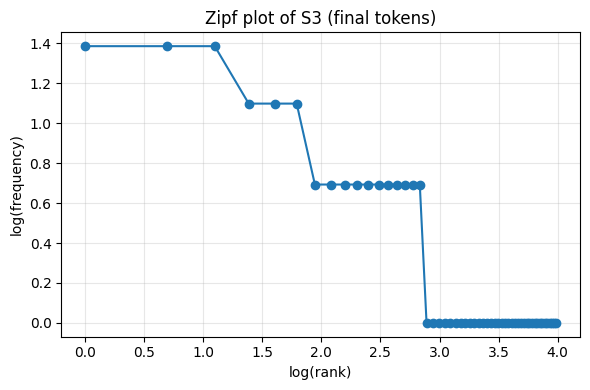

Top 5 bigrams in S1:
  ('.', 'is'): 4
  ('the', 'password'): 4
  ('is', 'there'): 3
  ('there', 'another'): 3
  ('another', 'solution'): 3

Top 5 bigrams in S3:
  ('another', 'solution'): 3
  ('showing', 'error'): 2
  ('stopped', 'responding'): 2
  ('tried', 'restarting'): 2
  ('restarting', 'password'): 2


In [12]:
import numpy as np
import matplotlib.pyplot as plt

porter = PorterStemmer()
S1 = [t for r in results.values() for t in r["tokens"]]          # all tokens
S2 = [t for t in S1 if not is_punct(t)]                          # no punctuation
S3 = [t for r in results.values() for t in r["final"]]           # final tokens
S4 = [porter.stem(t) for t in S3]                                # S3 after Porter

stats = pd.DataFrame([
    {"Set": name, "Total_Tokens": len(S), "Unique_Tokens": len(set(S)), "TTR": round(len(set(S)) / len(S), 4)}
    for name, S in [("S1 all tokens", S1), ("S2 no punctuation", S2), ("S3 final tokens", S3), ("S4 S3 + Porter", S4)]
])
print(stats.to_string(index=False))

# ---- top 10 words of S1 and S3 ----
print("\nTop 10 words in S1:")
print(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Freq"]).to_string(index=False))
print("\nTop 10 words in S3:")
print(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Freq"]).to_string(index=False))

# ---- log(rank) vs log(frequency) for S3 ----
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freqs), "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot of S3 (final tokens)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- top 5 bigrams (built inside each ticket so they never span two tickets) ----
def top_bigrams(token_lists, n=5):
    c = Counter()
    for toks in token_lists:
        c.update(zip(toks, toks[1:]))
    return c.most_common(n)

print("Top 5 bigrams in S1:")
for bg, c in top_bigrams([r["tokens"] for r in results.values()]):
    print(f"  {bg}: {c}")
print("\nTop 5 bigrams in S3:")
for bg, c in top_bigrams([r["final"] for r in results.values()]):
    print(f"  {bg}: {c}")

**Observe:** Why does TTR change from S1 to S4 in your data?

**Observe — answer:** TTR = unique tokens / total tokens. Removing punctuation (S1→S2) and stopwords (S2→S3) deletes many *repeated* tokens (`.`, `the`, `is`, `i`), so the total falls much faster than the unique count and TTR **rises**. Stemming (S3→S4) leaves the total unchanged but merges inflected forms (e.g. `worked`/`working`/`works` → `work`), so the unique count drops and TTR **falls** slightly. The cell below prints the actual numbers.

In [13]:
t = {row["Set"][:2]: row["TTR"] for _, row in stats.iterrows()}
for a, b in [("S1", "S2"), ("S2", "S3"), ("S3", "S4")]:
    direction = "rises" if t[b] > t[a] else "falls" if t[b] < t[a] else "stays the same"
    print(f"{a} -> {b}: TTR {t[a]:.4f} -> {t[b]:.4f}  ({direction})")
print(f"Overall S1 -> S4: {t['S1']:.4f} -> {t['S4']:.4f}")

S1 -> S2: TTR 0.4971 -> 0.5556  (rises)
S2 -> S3: TTR 0.5556 -> 0.6750  (rises)
S3 -> S4: TTR 0.6750 -> 0.6500  (falls)
Overall S1 -> S4: 0.4971 -> 0.6500
